## ML Assignment 2


## Framingham Heart Disease Classification

### Project Overview

This project focuses on predicting the 10-year risk of Coronary Heart Disease (CHD) using machine learning classification algorithms.

The objective is to build and compare five classification models and identify the most suitable model based on evaluation metrics, particularly Recall.

The project uses the Framingham Heart Disease dataset, which contains demographic, behavioral, and medical information about individuals.

In [53]:
import numpy as np
import pandas as pd
import time
import os
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

### Examine dataset size, missing values, and feature types (Data Preprocessing)

In [54]:
# Dataset loading

df = pd.read_csv("framingham.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [55]:
# dataset information
print("Dataset Information:")

df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 5

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [56]:
# Finding missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Feature': missing_values.index,
    'Missing Values': missing_values.values,
    'Percentage': (
        missing_values.values / len(df)
    ) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(
    by='Missing Values',
    ascending=False
)

display(missing_summary)

print(
    "Total missing values:",
    df.isnull().sum().sum()
)

,Feature,Missing Values,Percentage
14,glucose,388,9.150943
2,education,105,2.476415
5,BPMeds,53,1.250000
9,totChol,50,1.179245
4,cigsPerDay,29,0.683962
12,BMI,19,0.448113
13,heartRate,1,0.023585


Total missing values: 645


In [57]:
# Removing duplicates
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Dataset shape after removing duplicates:",
      df.shape)

Duplicate records: 0
Dataset shape after removing duplicates: (4240, 16)


In [58]:
X = df.drop(columns=['TenYearCHD'])

y = df['TenYearCHD']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("Overall Target Class Distribution:")
print(y.value_counts())

print("\nClass Distribution Percentage:")
print(y.value_counts(normalize=True) * 100)

Input shape: (4240, 15)
Target shape: (4240,)
Overall Target Class Distribution:
TenYearCHD
0    3596
1     644
Name: count, dtype: int64

Class Distribution Percentage:
TenYearCHD
0    84.811321
1    15.188679
Name: proportion, dtype: float64


In [59]:
# Features
categorical_features = [
    'male',
    'education',
    'currentSmoker',
    'BPMeds',
    'prevalentStroke',
    'prevalentHyp',
    'diabetes'
]

numerical_features = [
    'age',
    'cigsPerDay',
    'totChol',
    'sysBP',
    'diaBP',
    'BMI',
    'heartRate',
    'glucose'
]

In [60]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (3392, 15)
Testing data: (848, 15)

Training class distribution:
TenYearCHD
0    84.817217
1    15.182783
Name: proportion, dtype: float64

Testing class distribution:
TenYearCHD
0    84.787736
1    15.212264
Name: proportion, dtype: float64


In [61]:
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [62]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training data:",
      X_train_processed.shape)

print("Processed testing data:",
      X_test_processed.shape)

print("Remaining missing values:",
      np.isnan(X_train_processed).sum())

Processed training data: (3392, 24)
Processed testing data: (848, 24)
Remaining missing values: 0


In [63]:
# Create and save test dataset

test_data = X_test.copy()
test_data['TenYearCHD'] = y_test

test_data.to_csv('/content/test_data.csv', index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

Test dataset saved successfully!
Test dataset shape: (848, 16)


### Machine Learning Classification models and Evaluation metrics

In [64]:
#Machine learning models
models = {
    'Logistic Regression': LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=2000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight='balanced'
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Naive Bayes (Gaussian)': GaussianNB(),

    'Random Forest': RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_estimators=300,
        class_weight='balanced',
        n_jobs=-1
    )
}

In [65]:
# Dictionary to hold evaluation metrics
metrics_summary = {}

# Train and evaluate each model
for name, model in models.items():
    # Fit the model
    model.fit(X_train_processed, y_train)

    # Predict class labels
    y_pred = model.predict(X_test_processed)

    # Predict class probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]


    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store metrics
    metrics_summary[name] = {
        'Accuracy': acc,
        'AUC-ROC': auc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'MCC': mcc
    }

    # Print evaluation details
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}\n")

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.91      0.68      0.78       719
           1       0.25      0.60      0.36       129

    accuracy                           0.67       848
   macro avg       0.58      0.64      0.57       848
weighted avg       0.81      0.67      0.71       848

Confusion Matrix:
[[491 228]
 [ 51  78]]

=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       719
           1       0.25      0.22      0.24       129

    accuracy                           0.78       848
   macro avg       0.56      0.55      0.55       848
weighted avg       0.77      0.78      0.77       848

Confusion Matrix:
[[632  87]
 [100  29]]

=== K-Nearest Neighbors ===
              precision    recall  f1-score   support

           0       0.86      0.98      0.91       719
           1       0.44      0.09      0.15       129

    accuracy        

In [66]:
# Display model comparison
df_metrics = pd.DataFrame(metrics_summary).T
df_metrics = df_metrics.round(4)

display(df_metrics.sort_values(by='AUC-ROC', ascending=False))

,Accuracy,AUC-ROC,Precision,Recall,F1-Score,MCC
Logistic Regression,0.6710,0.6981,0.2549,0.6047,0.3586,0.2150
Naive Bayes (Gaussian),0.8149,0.6754,0.2667,0.1240,0.1693,0.0880
Random Forest,0.8467,0.6430,0.4286,0.0233,0.0441,0.0702
K-Nearest Neighbors,0.8443,0.5655,0.4444,0.0930,0.1538,0.1476
Decision Tree,0.7795,0.5519,0.2500,0.2248,0.2367,0.1085


### Model Comparision Visualization

<Figure size 1400x700 with 0 Axes>

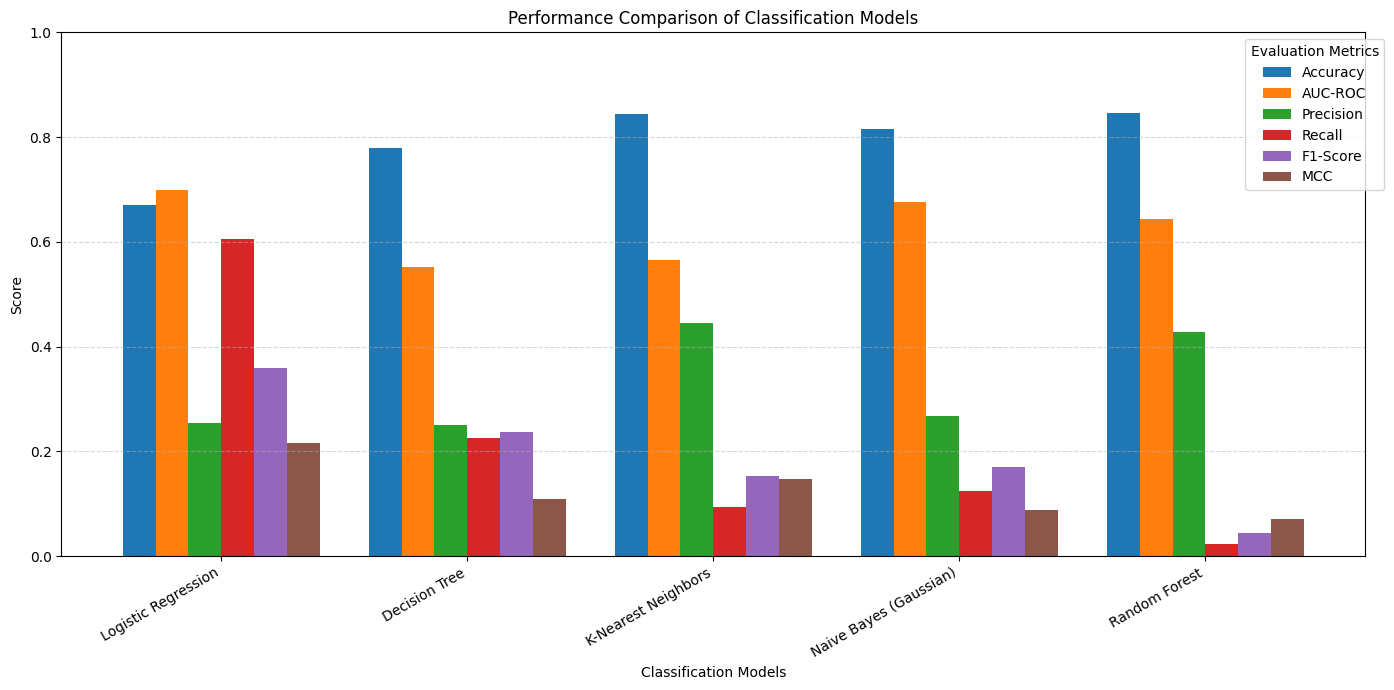

In [67]:
os.makedirs('results', exist_ok=True)

# Plot model comparison
plt.figure(figsize=(14, 7))

df_metrics.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics', bbox_to_anchor=(1.02, 1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(
    'results/performance_comparison.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

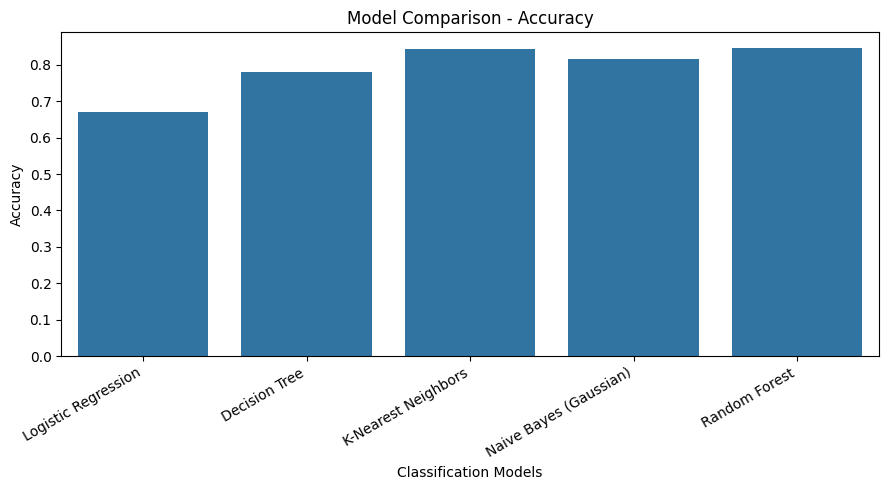

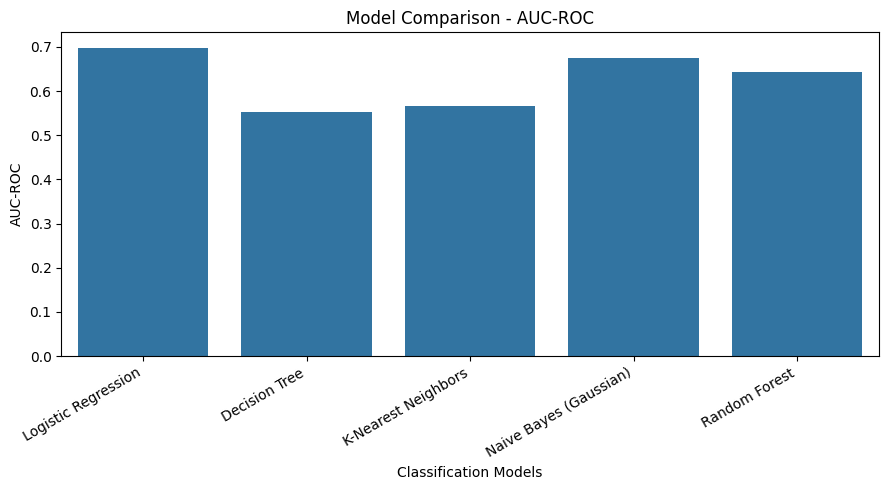

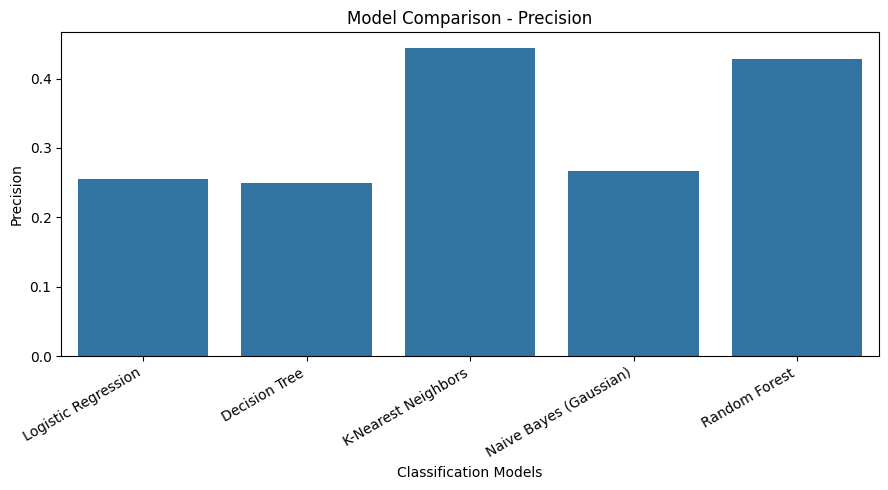

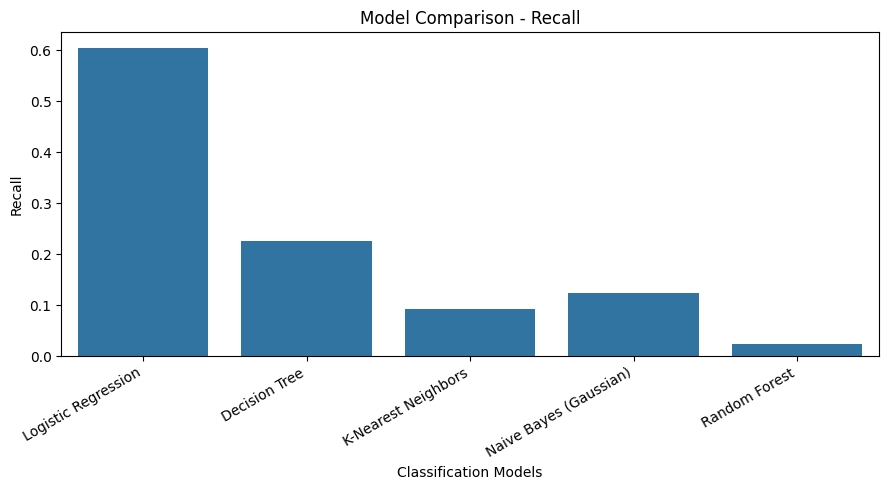

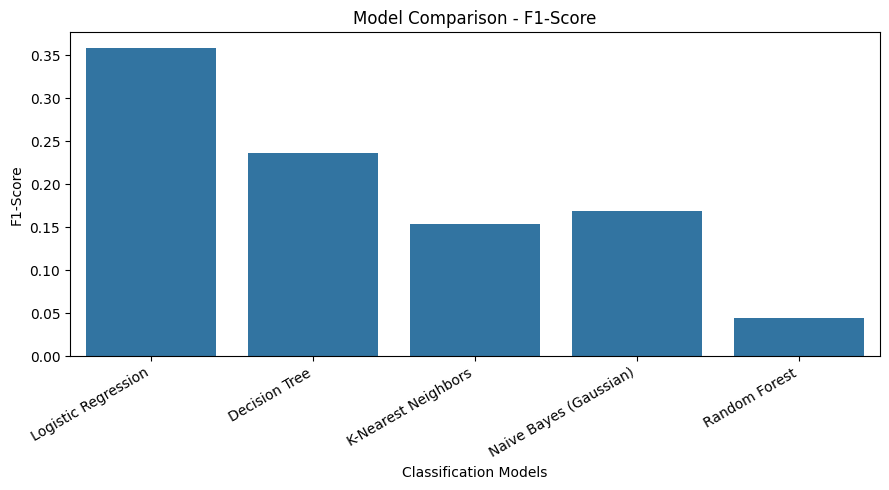

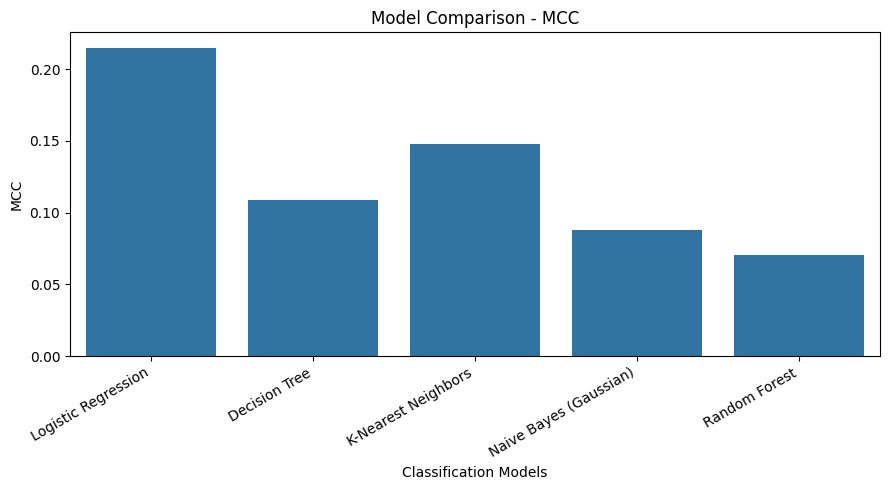

In [68]:
metrics = [
    'Accuracy', 'AUC-ROC', 'Precision',
    'Recall', 'F1-Score', 'MCC'
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=df_metrics.index,
        y=df_metrics[metric]
    )

    plt.title(f'Model Comparison - {metric}')
    plt.xlabel('Classification Models')
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()

    # Save each chart with a unique filename
    filename = metric.lower().replace('-', '_')

    plt.savefig(
        f'results/{filename}.png',
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()

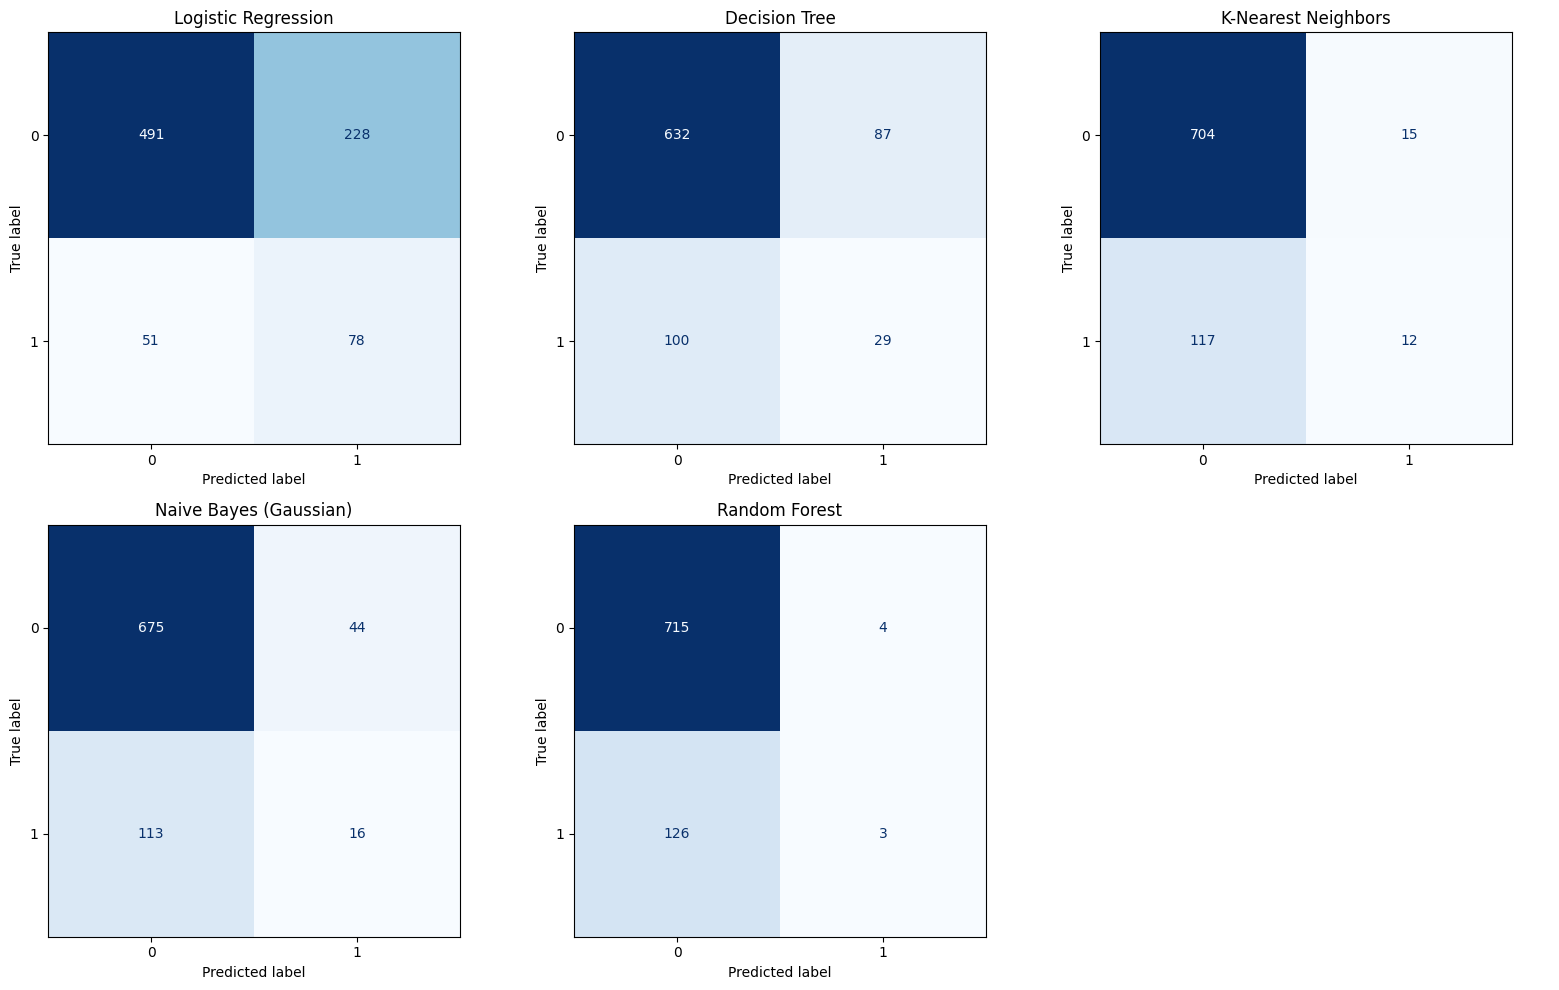

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    y_pred = model.predict(X_test_processed)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        ax=axes[i],
        cmap='Blues',
        colorbar=False
    )

    axes[i].set_title(name)

# Hide unused sixth subplot
axes[5].axis('off')

plt.tight_layout()

# Save confusion matrices
plt.savefig(
    'results/confusion_matrices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [70]:
# Identify the model with the highest recall
best_model_name = df_metrics['Recall'].idxmax()

print("Best Model based on Recall:", best_model_name)
print("Recall:", df_metrics.loc[best_model_name, 'Recall'])

# Display all metrics for the selected model
print("\nPerformance of the selected model:")
display(df_metrics.loc[[best_model_name]])

Best Model based on Recall: Logistic Regression
Recall: 0.6047

Performance of the selected model:


,Accuracy,AUC-ROC,Precision,Recall,F1-Score,MCC
Logistic Regression,0.671,0.6981,0.2549,0.6047,0.3586,0.215


In [71]:
df_metrics.to_csv(
    'results/model_comparison.csv',
    index=True
)
print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [72]:
# Create model folder if it doesn't exist
os.makedirs('model', exist_ok=True)

# Save all trained models
for name, model in models.items():

    filename = name.lower().replace(' ', '_')
    filename = filename.replace('(', '').replace(')', '')

    joblib.dump(model, f'model/{filename}.pkl')

print("All trained models saved successfully!")

# Save the fitted preprocessor
joblib.dump(
    preprocessor,
    'model/preprocessor.pkl'
)

print("Preprocessor saved successfully!")

print("\nAll model files saved in the 'model' folder.")

All trained models saved successfully!
Preprocessor saved successfully!

All model files saved in the 'model' folder.
